In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier , plot_tree, DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsClassifier , KNeighborsRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import accuracy_score, r2_score


from tqdm import tqdm 


from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")
import os 
os.chdir('E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets\Cases\Wisconsin')

In [6]:
bcancer = pd.read_csv('BreastCancer.csv',index_col=0)
bcancer

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign
...,...,...,...,...,...,...,...,...,...,...
1369821,10,10,10,10,5,10,10,10,7,Malignant
1371026,5,10,10,10,4,10,5,6,3,Malignant
1371920,5,1,1,1,2,1,3,2,1,Benign


In [7]:
X,y = bcancer.drop('Class', axis = 1) , bcancer['Class']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26, stratify=y)

In [10]:
rf = RandomForestClassifier(max_features=2, n_estimators=50,random_state=26)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test, y_pred)

0.9666666666666667

In [19]:
rf = RandomForestClassifier(max_features=2, n_estimators=50,random_state=26)
rf.fit(X_test, y_test)
y_pred = rf.predict(X_train)
accuracy_score(y_train, y_pred)

0.9529652351738241

In [14]:
m_feat = [2,3,4,5]
n_samples = [25,50,100]
scores = []
for m in m_feat:
    for n in n_samples:
        rf = RandomForestClassifier(max_features=m, n_estimators=n,random_state=26)

        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_test)
        scores.append([m, n , accuracy_score(y_test, y_pred)])

df_scores = pd.DataFrame(scores, columns=['Features','n','Score'])
df_scores.sort_values(by='Score',ascending=False)

,Features,n,Score
0,2,25,0.966667
1,2,50,0.966667
2,2,100,0.966667
4,3,50,0.966667
11,5,100,0.966667
5,3,100,0.966667
7,4,50,0.966667
8,4,100,0.966667
10,5,50,0.966667
3,3,25,0.961905


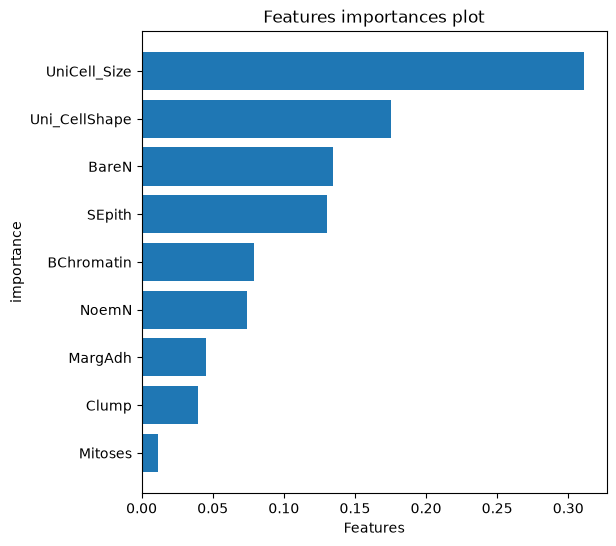

In [22]:
 

bestTree = RandomForestClassifier(max_features=2, n_estimators=25,random_state=26)
 
bestTree.fit(X_train , y_train)

df_imp = pd.DataFrame({'features':list(X_train.columns),
                          'importance': bestTree.feature_importances_})

df_imp.sort_values('importance',inplace=True)
plt.figure(figsize=(6,6))
plt.barh(df_imp['features'], df_imp['importance'])
plt.xlabel('Features')
plt.ylabel('importance')
plt.title('Features importances plot')

plt.show()